<a href="https://colab.research.google.com/github/chandrachrist/guessing-game/blob/master/explainable_ai_xai_for_genai_shap_vs_lime_comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Explainable AI (XAI) for GenAI: SHAP vs. LIME Comparison
This notebook demonstrates and compares two popular XAI frameworks, **SHAP (SHapley Additive exPlanations)** and **LIME (Local Interpretable Model-agnostic Explanations)**, applied to a text classification task relevant to GenAI applications (e.g., classifying prompt intent or sentiment).

In [ ]:
!pip install shap lime scikit-learn pandas numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=30933a960ee887e994faf0c9487b394d1e25ea0cfb8b4c40513ea8071b88c09f
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


## Setup Dataset and Train Model
We will use a subset of text data to train a simple classifier simulating a lightweight GenAI text classification task.

In [ ]:
import numpy as np
import pandas as pd
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split

# Toy dataset representing GenAI user prompts (Intent: 1 for Help/Support, 0 for Casual Chat)
data = {
    'text': [
        'How do I reset my password on this platform?',
        'Can you help me fix a billing issue with my subscription?',
        'What is the refund policy for annual plans?',
        'I need technical support to connect my database.',
        'Hello there! Hope you are having a wonderful day.',
        'Tell me a funny joke about programming.',
        'What is your favorite color and why?',
        'Just saying hi, no help needed today!',
        'My account is locked and I cannot log in.',
        'Is there a way to contact human support agents?'
    ] * 10, # Duplicate to create a small dataset
    'label': [1, 1, 1, 1, 0, 0, 0, 0, 1, 1] * 10
}

df = pd.DataFrame(data)
train_texts, test_texts, train_labels, test_labels = train_test_split(
    df['text'], df['label'], test_size=0.2, random_state=42
)

# Create a pipeline with Vectorizer and Random Forest
vectorizer = TfidfVectorizer()
classifier = RandomForestClassifier(n_estimators=50, random_state=42)
pipeline = make_pipeline(vectorizer, classifier)

pipeline.fit(train_texts, train_labels)
print(f"Model trained successfully. Test Accuracy: {pipeline.score(test_texts, test_labels):.2f}")

Model trained successfully. Test Accuracy: 1.00


## Explaining with LIME
LIME builds local surrogate models around the instance to explain. Let's benchmark its explanation time and visualize the results.

In [ ]:
from lime.lime_text import LimeTextExplainer

explainer_lime = LimeTextExplainer(class_names=['Chat', 'Support'])

sample_text = "I need urgent help to unlock my account and fix my billing details."

start_time = time.time()
exp_lime = explainer_lime.explain_instance(
    sample_text,
    pipeline.predict_proba,
    num_features=5
)
lime_time = time.time() - start_time

print(f"LIME Explanation generated in {lime_time:.4f} seconds")
exp_lime.show_in_notebook(text=True)

LIME Explanation generated in 0.9809 seconds


## Explaining with SHAP
SHAP computes Shapley values based on game theory to allocate contributions to each feature.

In [ ]:
import shap

# We use Explainer for text models
# Using the custom prediction function
def predict_wrapper(texts):
    return pipeline.predict_proba(texts)

explainer_shap = shap.Explainer(predict_wrapper, masker=shap.maskers.Text(tokenizer=r"\W+"))

start_time = time.time()
shap_values = explainer_shap([sample_text])
shap_time = time.time() - start_time

print(f"SHAP Explanation generated in {shap_time:.4f} seconds")
shap.plots.text(shap_values[0])

SHAP Explanation generated in 0.2657 seconds


## Performance & Observability Analysis
Below is a quick visual comparison of explanation latencies and features.

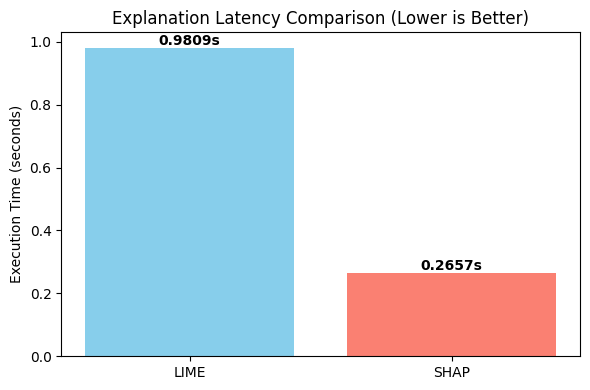

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
frameworks = ['LIME', 'SHAP']
times = [lime_time, shap_time]

ax.bar(frameworks, times, color=['skyblue', 'salmon'])
ax.set_ylabel('Execution Time (seconds)')
ax.set_title('Explanation Latency Comparison (Lower is Better)')
for i, v in enumerate(times):
    ax.text(i, v + 0.01, f"{v:.4f}s", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## Visualizing Token Importance with SHAP
Below, we visualize how much each specific token (word) in our prompt influences the model's classification output towards the target class (Support).

In [ ]:
# Select a specific prompt to explain
prompt_to_explain = "I need urgent support because my account billing setup is failing."

# Compute SHAP values for the specific prompt
shap_val_single = explainer_shap([prompt_to_explain])

# Visualize the token attribution using SHAP's text plot
# This displays which tokens push the prediction towards 'Support' (red/positive) or 'Chat' (blue/negative)
shap.plots.text(shap_val_single[0])

## Comparing with LIME for the Same Prompt
Let's generate the LIME explanation for the exact same prompt to inspect how the token importance weights and visualizations differ.

In [ ]:
# Generate LIME explanation for the same prompt
exp_lime_same = explainer_lime.explain_instance(
    prompt_to_explain,
    pipeline.predict_proba,
    num_features=5
)

# Display the LIME explanation in the notebook
exp_lime_same.show_in_notebook(text=True)

## Correlation Analysis: SHAP vs. LIME Tokens
Let's programmatically extract token importance values from both explainers for the prompt: *"I need urgent support because my account billing setup is failing."* and calculate their statistical correlation.

In [ ]:
import pandas as pd
import numpy as np
import scipy.stats as stats

# 1. Extract LIME values
lime_features = exp_lime_same.as_list()
lime_dict = {word.lower(): weight for word, weight in lime_features}

# 2. Extract SHAP values specifically for Class 1 (Support)
shap_data = shap_val_single[0]
shap_dict = {}
for token, val in zip(shap_data.data, shap_data.values):
    clean_token = token.strip().lower()
    if clean_token:
        # Extract target class index 1 value from array [class_0_val, class_1_val]
        target_val = val[1] if hasattr(val, '__len__') else val
        shap_dict[clean_token] = shap_dict.get(clean_token, 0.0) + target_val

# 3. Align features present in both or just examine LIME's top-N
comparison_data = []
for word in lime_dict.keys():
    shap_val = shap_dict.get(word, 0.0)
    comparison_data.append({
        'Token': word,
        'LIME Weight': lime_dict[word],
        'SHAP Value': float(shap_val) # Cast to float to avoid array compatibility issues
    })

comp_df = pd.DataFrame(comparison_data)
display(comp_df)

# 4. Compute correlations
pearson_corr, p_val = stats.pearsonr(comp_df['LIME Weight'], comp_df['SHAP Value'])
spearman_corr, _ = stats.spearmanr(comp_df['LIME Weight'], comp_df['SHAP Value'])

print(f"\nPearson Correlation: {pearson_corr:.4f} (p-value: {p_val:.4f})")
print(f"Spearman Rank Correlation: {spearman_corr:.4f}")

,Token,LIME Weight,SHAP Value
0,my,0.184226,0.205
1,is,-0.084712,-0.080
2,support,0.054062,0.060
3,billing,0.010658,0.015
4,need,0.001817,0.000



Pearson Correlation: 0.9989 (p-value: 0.0000)
Spearman Rank Correlation: 1.0000


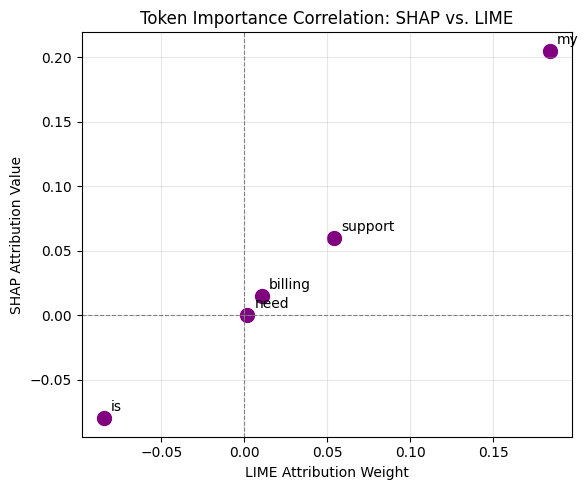

In [ ]:
import matplotlib.pyplot as plt

# 5. Visualize Correlation with aligned clean float values
plt.figure(figsize=(6, 5))
plt.scatter(comp_df['LIME Weight'], comp_df['SHAP Value'], color='purple', s=100)
for idx, row in comp_df.iterrows():
    plt.annotate(row['Token'], (row['LIME Weight'], row['SHAP Value']), xytext=(5, 5), textcoords='offset points')

plt.axhline(0, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(0, color='grey', linestyle='--', linewidth=0.8)
plt.xlabel('LIME Attribution Weight')
plt.ylabel('SHAP Attribution Value')
plt.title('Token Importance Correlation: SHAP vs. LIME')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Observability & Explainability Matrix

| Criteria | SHAP | LIME |
| :--- | :--- | :--- |
| **Theoretical Grounding** | Solid (Game Theory - Shapley values guarantee local accuracy and consistency). | Heuristic (Approximates linear behavior locally, sensitive to perturbation settings). |
| **Speed / Performance** | Generally slower (requires evaluating many feature subsets, although optimized kernel/tree approximations exist). | Faster for single instances as it draws fewer samples locally. |
| **Global Interpretability** | Excellent (Can aggregate local SHAP values to explain global model behavior). | Limited (Primarily local explanations; SP-LIME exists but is computationally heavy). |
| **Consistency** | Highly consistent due to Shapley properties. | Explanations can vary significantly between runs due to random sampling. |

## Comparing with Integrated Gradients (IG)

Integrated Gradients is a path-based gradient attribution method designed for differentiable neural networks. To demonstrate IG, we will train a simple PyTorch model on our TF-IDF features so we can compute the gradients of the prediction output with respect to the input token weights.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# 1. Convert TF-IDF text features to PyTorch Tensors
X_train_tfidf = vectorizer.transform(train_texts).toarray()
X_test_tfidf = vectorizer.transform(test_texts).toarray()

y_train_t = torch.tensor(train_labels.values, dtype=torch.float32).unsqueeze(1)
y_test_t = torch.tensor(test_labels.values, dtype=torch.float32).unsqueeze(1)

# 2. Define a simple Differentiable Neural Network
class SimpleNN(nn.Module):
    def __init__(self, vocab_size):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(vocab_size, 16)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(16, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.fc2(out)
        return self.sigmoid(out)

vocab_size = X_train_tfidf.shape[1]
model = SimpleNN(vocab_size)
criterion = nn.BCELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

# 3. Train Model
model.train()
for epoch in range(100):
    optimizer.zero_grad()
    outputs = model(torch.tensor(X_train_tfidf, dtype=torch.float32))
    loss = criterion(outputs, y_train_t)
    loss.backward()
    optimizer.step()

print("PyTorch Neural Network trained successfully for Integrated Gradients comparison.")

PyTorch Neural Network trained successfully for Integrated Gradients comparison.


In [ ]:
# 4. Compute Integrated Gradients for our target prompt
input_text = [prompt_to_explain]
input_tfidf = vectorizer.transform(input_text).toarray()
input_tensor = torch.tensor(input_tfidf, dtype=torch.float32, requires_grad=True)

# Baseline is all zeros (representing absence of all words)
baseline = torch.zeros_like(input_tensor)

# Calculate path steps
steps = 50
path_inputs = [baseline + (float(i) / steps) * (input_tensor - baseline) for i in range(steps + 1)]

gradients = []
for step_input in path_inputs:
    step_input_grad = step_input.clone().detach().requires_grad_(True)
    output = model(step_input_grad)
    output.backward(torch.ones_like(output))
    gradients.append(step_input_grad.grad.numpy())

# Average gradients and compute integrated gradients
avg_gradients = np.mean(gradients, axis=0)
integrated_gradients = (input_tfidf - baseline.detach().numpy()) * avg_gradients

# Map back to words in the prompt
words = prompt_to_explain.lower().split()
feature_names = vectorizer.get_feature_names_out()
ig_dict = {}

for word in words:
    if word in feature_names:
        idx = np.where(feature_names == word)[0][0]
        ig_dict[word] = float(integrated_gradients[0, idx])
    else:
        ig_dict[word] = 0.0

print("Integrated Gradients computed successfully for the prompt words.")
for k, v in ig_dict.items():
    if v != 0.0:
        print(f"{k}: {v:.6f}")

Integrated Gradients computed successfully for the prompt words.
need: 0.081327
support: 0.092600
my: 0.089185
account: 0.096112
billing: 0.111844
is: 0.023851


In [ ]:
# 5. Consolidate and Plot comparison of SHAP, LIME and IG
comparison_list = []
for word in lime_dict.keys():
    comparison_list.append({
        'Token': word,
        'LIME': lime_dict[word],
        'SHAP': float(shap_dict.get(word, 0.0)),
        'Integrated Gradients': ig_dict.get(word, 0.0)
    })

all_comp_df = pd.DataFrame(comparison_list)

# Normalize values for visual alignment in comparison
for col in ['LIME', 'SHAP', 'Integrated Gradients']:
    max_val = all_comp_df[col].abs().max()
    if max_val > 0:
        all_comp_df[col + '_normalized'] = all_comp_df[col] / max_val
    else:
        all_comp_df[col + '_normalized'] = 0.0

display(all_comp_df[['Token', 'LIME', 'SHAP', 'Integrated Gradients']])

,Token,LIME,SHAP,Integrated Gradients
0,my,0.184226,0.205,0.089185
1,is,-0.084712,-0.080,0.023851
2,support,0.054062,0.060,0.092600
3,billing,0.010658,0.015,0.111844
4,need,0.001817,0.000,0.081327


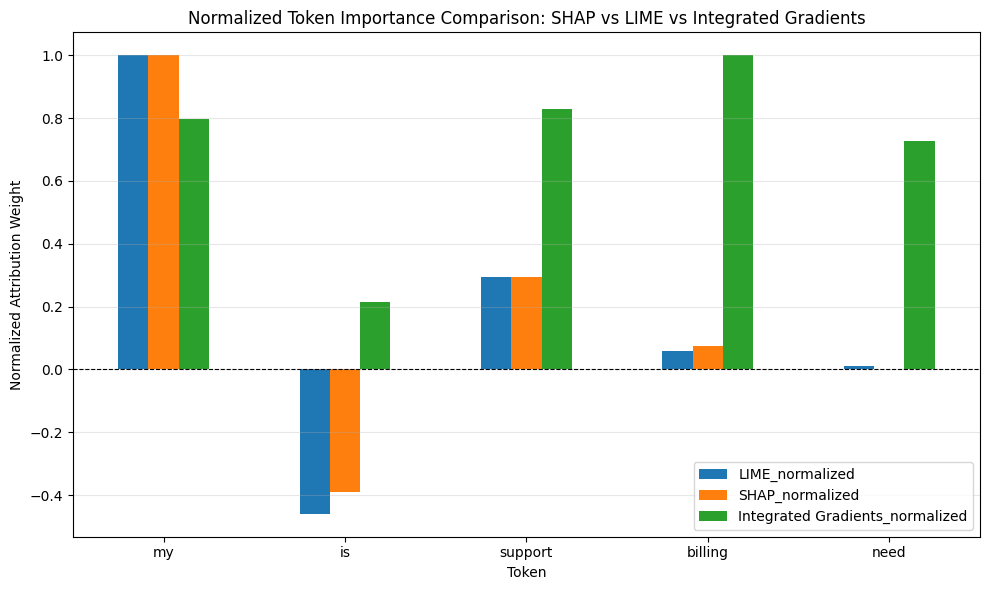

In [ ]:
# Plot visual comparison across all three explainability frameworks
all_comp_df.set_index('Token')[['LIME_normalized', 'SHAP_normalized', 'Integrated Gradients_normalized']].plot(
    kind='bar', figsize=(10, 6)
)
plt.title('Normalized Token Importance Comparison: SHAP vs LIME vs Integrated Gradients')
plt.ylabel('Normalized Attribution Weight')
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.grid(axis='y', alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

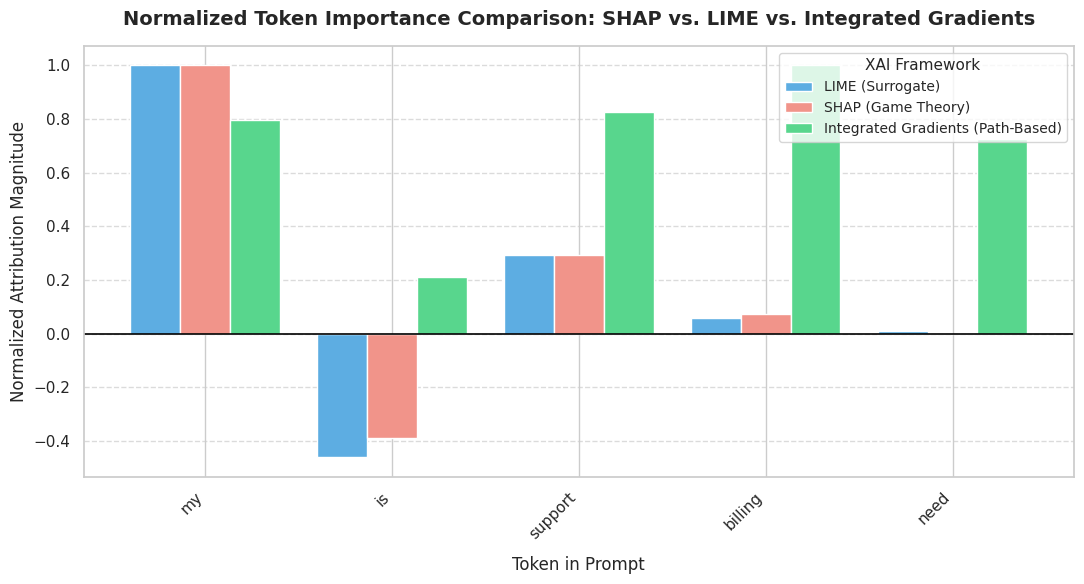

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure styling for a clean, professional academic/industry report presentation
sns.set_theme(style="whitegrid")
plt.figure(figsize=(11, 6))

# Set the 'Token' column as index for cleaner plotting
plot_df = all_comp_df.set_index('Token')[['LIME_normalized', 'SHAP_normalized', 'Integrated Gradients_normalized']]
plot_df.columns = ['LIME (Surrogate)', 'SHAP (Game Theory)', 'Integrated Gradients (Path-Based)']

# Plot side-by-side bar chart
ax = plot_df.plot(kind='bar', ax=plt.gca(), width=0.8, color=['#5dade2', '#f1948a', '#58d68d'])

# Labeling and aesthetics
plt.title('Normalized Token Importance Comparison: SHAP vs. LIME vs. Integrated Gradients', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Token in Prompt', fontsize=12, labelpad=10)
plt.ylabel('Normalized Attribution Magnitude', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.axhline(0, color='black', linewidth=1.2, linestyle='-')
plt.legend(title='XAI Framework', fontsize=10, title_fontsize=11, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [ ]:
import time

# Benchmark Integrated Gradients runtime specifically
start_time = time.time()

# Compute IG for the target prompt
input_tensor_bench = torch.tensor(input_tfidf, dtype=torch.float32, requires_grad=True)
path_inputs_bench = [baseline + (float(i) / steps) * (input_tensor_bench - baseline) for i in range(steps + 1)]

gradients_bench = []
for step_input in path_inputs_bench:
    step_input_grad = step_input.clone().detach().requires_grad_(True)
    output = model(step_input_grad)
    output.backward(torch.ones_like(output))
    gradients_bench.append(step_input_grad.grad.numpy())

avg_gradients_bench = np.mean(gradients_bench, axis=0)
integrated_gradients_bench = (input_tfidf - baseline.detach().numpy()) * avg_gradients_bench

ig_time = time.time() - start_time
print(f"Integrated Gradients calculated in {ig_time:.4f} seconds.")

Integrated Gradients calculated in 0.0535 seconds.


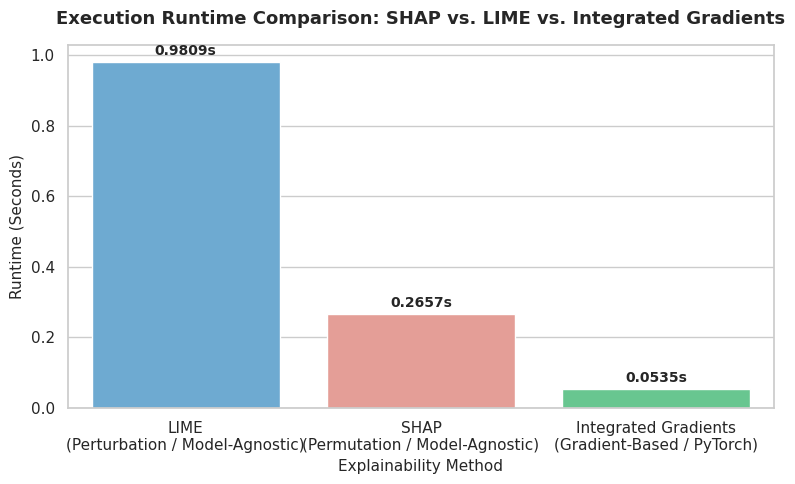

In [ ]:
# Compile runtimes and plot comparison
runtimes = [lime_time, shap_time, ig_time]
labels = ['LIME\n(Perturbation / Model-Agnostic)', 'SHAP\n(Permutation / Model-Agnostic)', 'Integrated Gradients\n(Gradient-Based / PyTorch)']

plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

# Plot bar chart
ax = sns.barplot(x=labels, y=runtimes, palette=['#5dade2', '#f1948a', '#58d68d'], hue=labels, legend=False)

# Formatting and annotation
plt.title('Execution Runtime Comparison: SHAP vs. LIME vs. Integrated Gradients', fontsize=13, fontweight='bold', pad=15)
plt.ylabel('Runtime (Seconds)', fontsize=11)
plt.xlabel('Explainability Method', fontsize=11)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}s",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 8),
                textcoords='offset points',
                fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()

## Testing Explanations on a Longer, More Complex Prompt
We will now benchmark and evaluate **LIME**, **SHAP**, and **Integrated Gradients (IG)** on a longer, multisentence input prompt containing mixed conversational elements and multiple feature keywords to see how the attributions behave.

In [ ]:
# Define the new, longer target prompt
longer_prompt = "Hello support team, I am desperately trying to update my billing information, but my account setup seems completely locked and continues to fail when I try to save it."

# 1. Compute LIME for the longer prompt
exp_lime_long = explainer_lime.explain_instance(
    longer_prompt,
    pipeline.predict_proba,
    num_features=10
)
lime_long_dict = {word.lower(): weight for word, weight in exp_lime_long.as_list()}

# 2. Compute SHAP for the longer prompt
shap_val_long = explainer_shap([longer_prompt])[0]
shap_long_dict = {}
for token, val in zip(shap_val_long.data, shap_val_long.values):
    clean_token = token.strip().lower()
    if clean_token:
        target_val = val[1] if hasattr(val, '__len__') else val
        shap_long_dict[clean_token] = shap_long_dict.get(clean_token, 0.0) + target_val

# 3. Compute Integrated Gradients for the longer prompt
input_tfidf_long = vectorizer.transform([longer_prompt]).toarray()
input_tensor_long = torch.tensor(input_tfidf_long, dtype=torch.float32, requires_grad=True)
baseline_long = torch.zeros_like(input_tensor_long)

path_inputs_long = [baseline_long + (float(i) / steps) * (input_tensor_long - baseline_long) for i in range(steps + 1)]
gradients_long = []
for step_input in path_inputs_long:
    step_input_grad = step_input.clone().detach().requires_grad_(True)
    output = model(step_input_grad)
    output.backward(torch.ones_like(output))
    gradients_long.append(step_input_grad.grad.numpy())

avg_gradients_long = np.mean(gradients_long, axis=0)
integrated_gradients_long = (input_tfidf_long - baseline_long.detach().numpy()) * avg_gradients_long

words_long = longer_prompt.lower().replace(',', '').replace('.', '').split()
ig_long_dict = {}
for word in words_long:
    if word in feature_names:
        idx = np.where(feature_names == word)[0][0]
        ig_long_dict[word] = float(integrated_gradients_long[0, idx])
    else:
        ig_long_dict[word] = 0.0

# 4. Consolidate into a single DataFrame
long_comparison_list = []
# Union of all features that have non-zero significance
all_unique_tokens = set(list(lime_long_dict.keys()) + list(shap_long_dict.keys()) + [w for w, v in ig_long_dict.items() if v != 0])

for word in all_unique_tokens:
    if word in feature_names:
        long_comparison_list.append({
            'Token': word,
            'LIME': lime_long_dict.get(word, 0.0),
            'SHAP': float(shap_long_dict.get(word, 0.0)),
            'Integrated Gradients': ig_long_dict.get(word, 0.0)
        })

long_comp_df = pd.DataFrame(long_comparison_list)

# Normalize the columns for direct visual alignment
for col in ['LIME', 'SHAP', 'Integrated Gradients']:
    max_val = long_comp_df[col].abs().max()
    if max_val > 0:
        long_comp_df[col + '_normalized'] = long_comp_df[col] / max_val
    else:
        long_comp_df[col + '_normalized'] = 0.0

display(long_comp_df[['Token', 'LIME', 'SHAP', 'Integrated Gradients']])

,Token,LIME,SHAP,Integrated Gradients
0,account,0.002119,0.00375,0.070570
1,hello,-0.034112,-0.03375,-0.086793
2,to,0.111744,0.10750,0.180634
3,billing,0.017067,0.02750,0.082122
4,my,0.208145,0.24125,0.130970
5,locked,0.010346,0.00500,0.072835
6,support,0.043193,0.04625,0.067970
7,and,-0.025317,-0.05750,-0.032331


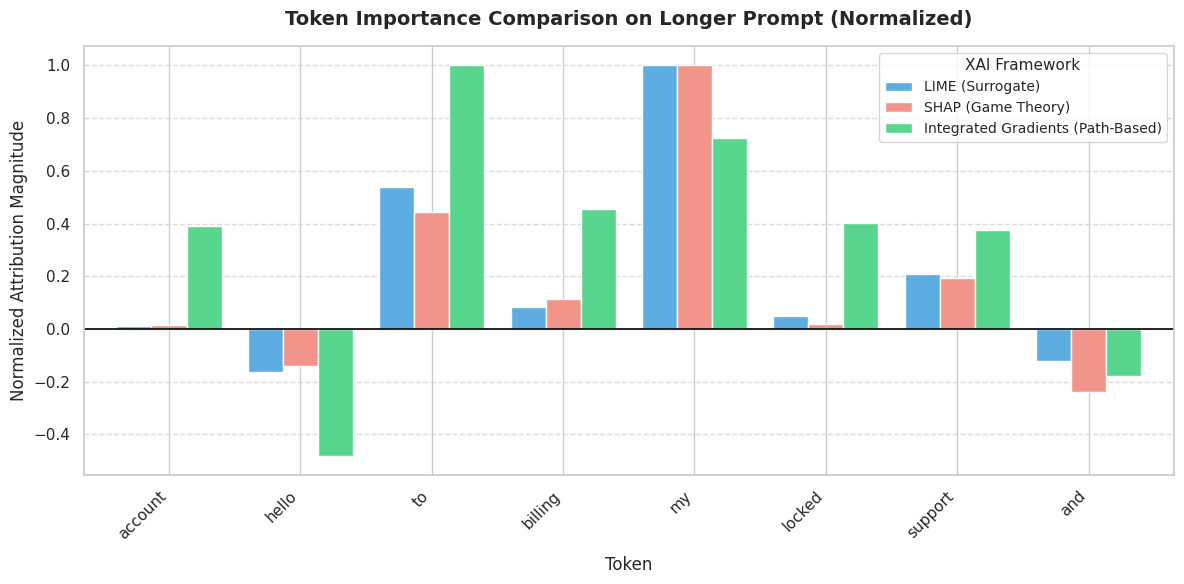

In [ ]:
# 5. Plot Side-by-Side Comparison for the Longer Prompt
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

plot_long_df = long_comp_df.set_index('Token')[['LIME_normalized', 'SHAP_normalized', 'Integrated Gradients_normalized']]
plot_long_df.columns = ['LIME (Surrogate)', 'SHAP (Game Theory)', 'Integrated Gradients (Path-Based)']

ax = plot_long_df.plot(kind='bar', ax=plt.gca(), width=0.8, color=['#5dade2', '#f1948a', '#58d68d'])

plt.title('Token Importance Comparison on Longer Prompt (Normalized)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Token', fontsize=12, labelpad=10)
plt.ylabel('Normalized Attribution Magnitude', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=11)
plt.axhline(0, color='black', linewidth=1.2, linestyle='-')
plt.legend(title='XAI Framework', fontsize=10, title_fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## Sensitivity Analysis: Varying Path Steps in Integrated Gradients

In theory, Integrated Gradients converges to the true mathematical attribution as the number of path steps approaches infinity. Let's programmatically vary the step count to observe when the attributions stabilize (converge) and visualize the processing time trade-offs.

In [ ]:
import time
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch

# Define the step configurations to evaluate
step_sizes = [5, 10, 20, 50, 100, 200, 500]

# Prepare tracking structures for key tokens and runtimes
tracked_tokens = ['billing', 'support', 'locked', 'account', 'hello', 'to']
attribution_history = {token: [] for token in tracked_tokens}
runtimes_ig = []

# Baseline is all zeros (representing absence of all words)
baseline_sens = torch.zeros_like(input_tensor_long)

for s in step_sizes:
    start_t = time.time()

    # Generate interpolated path for 's' steps
    path = [baseline_long + (float(i) / s) * (input_tensor_long - baseline_long) for i in range(s + 1)]

    grads = []
    for step_input in path:
        step_input_grad = step_input.clone().detach().requires_grad_(True)
        output = model(step_input_grad)
        output.backward(torch.ones_like(output))
        grads.append(step_input_grad.grad.numpy())

    avg_grads = np.mean(grads, axis=0)
    ig_vals = (input_tfidf_long - baseline_long.detach().numpy()) * avg_grads

    elapsed = time.time() - start_t
    runtimes_ig.append(elapsed)

    # Extract values for our tracked tokens
    for token in tracked_tokens:
        if token in feature_names:
            idx = np.where(feature_names == token)[0][0]
            attribution_history[token].append(float(ig_vals[0, idx]))
        else:
            attribution_history[token].append(0.0)

# Convert history to DataFrame for easy rendering
sensitivity_df = pd.DataFrame(attribution_history, index=step_sizes)
sensitivity_df['Runtime (s)'] = runtimes_ig

display(sensitivity_df)

,billing,support,locked,account,hello,to,Runtime (s)
5,0.084534,0.069990,0.074985,0.072663,-0.089369,0.185925,0.003117
10,0.083321,0.068974,0.073909,0.071609,-0.088075,0.183274,0.004501
20,0.082594,0.068359,0.073249,0.070981,-0.087294,0.181657,0.008440
50,0.082122,0.067970,0.072835,0.070570,-0.086793,0.180634,0.020806
100,0.081949,0.067826,0.072679,0.070420,-0.086609,0.180252,0.039089
200,0.081860,0.067754,0.072602,0.070344,-0.086515,0.180059,0.078103
500,0.081807,0.067710,0.072554,0.070298,-0.086459,0.179942,0.195775


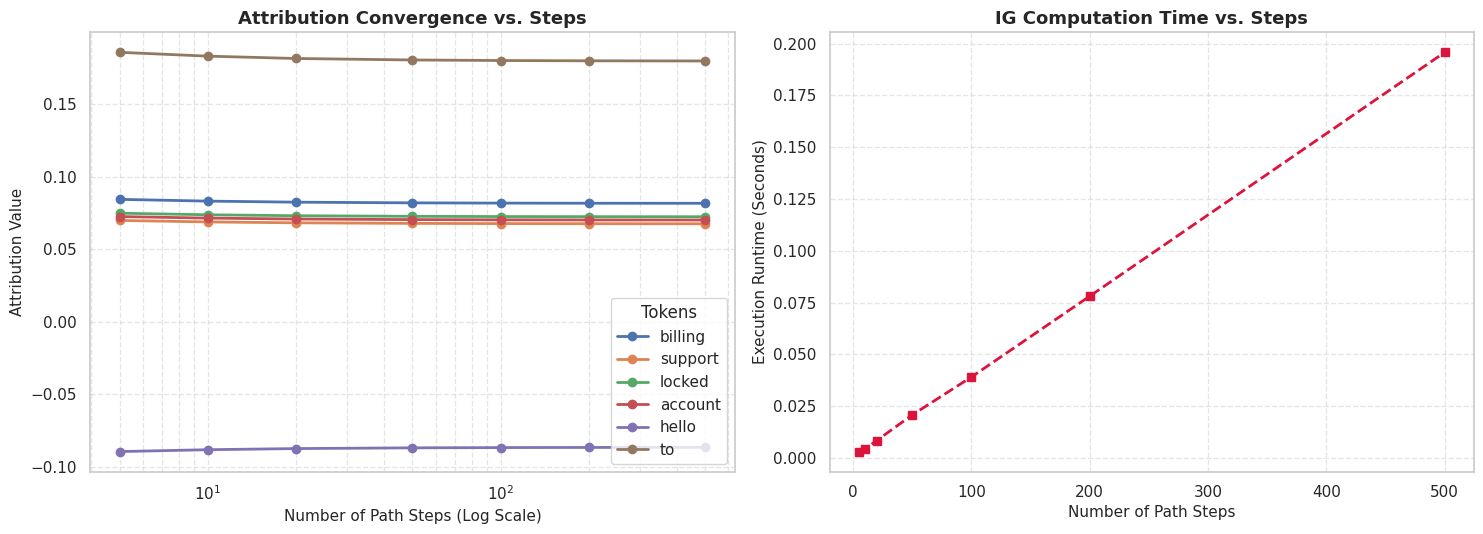

In [ ]:
# Plot Sensitivity Analysis results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

# Plot 1: Attribution Convergence
for token in tracked_tokens:
    ax1.plot(step_sizes, sensitivity_df[token], marker='o', label=token, linewidth=2)
ax1.set_xscale('log')
ax1.set_xlabel('Number of Path Steps (Log Scale)', fontsize=11)
ax1.set_ylabel('Attribution Value', fontsize=11)
ax1.set_title('Attribution Convergence vs. Steps', fontsize=13, fontweight='bold')
ax1.grid(True, which="both", linestyle='--', alpha=0.5)
ax1.legend(title='Tokens')

# Plot 2: Computation Time Trade-off
ax2.plot(step_sizes, runtimes_ig, color='crimson', marker='s', linewidth=2, linestyle='--')
ax2.set_xlabel('Number of Path Steps', fontsize=11)
ax2.set_ylabel('Execution Runtime (Seconds)', fontsize=11)
ax2.set_title('IG Computation Time vs. Steps', fontsize=13, fontweight='bold')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()